# [EURON 11기 Research] 11주차 복습과제 — MAE
**Masked Autoencoders Are Scalable Vision Learners** (He et al., CVPR 2022)

이번 복습과제는 세 파트로 구성되어 있습니다.

| 파트 | 내용 | 비고 |
|---|---|---|
| Part 1 | 개념 확인 (단답·서술) | 마크다운 셀에 답 작성 |
| Part 2 | MAE 핵심 로직 직접 구현 (patchify · random masking · masked MSE) | `____` 빈칸 채우기, CPU로 실행 가능 |
| Part 3 | 사전학습된 MAE로 재구성 실험 (Hugging Face `ViTMAEForPreTraining`) | 4주차 ViT 실습(교재 10장)과 같은 FashionMNIST 파이프라인 사용 |
| (선택) Part 4 | 토의 질문 | 자유 서술 |

**제출 방법**
- 이 노트북의 **사본**을 만들어 빈칸을 채우고 모든 셀을 실행한 뒤 `.ipynb`로 제출해 주세요.
- 파일명 & Pull Request 제목: `Week11복습과제_김이화` / 라벨: `복습과제` / branch: `Week_11`
- 코드, 실행 결과, 주석이 모두 포함되도록 해 주세요.

> 런타임: Part 2는 CPU로 충분합니다. Part 3는 GPU(런타임 → 런타임 유형 변경 → T4)를 권장하지만 CPU로도 실행됩니다.

---
## Part 1. 개념 확인

아래 질문에 1~3문장으로 답해 주세요. (발표 자료 #01~#04 참고)

**Q1.** 논문은 NLP와 비교해 비전에서 masked autoencoding이 늦게 발전한 이유를 세 가지 관점으로 설명합니다. 세 관점을 쓰고, 그중 **information density** 관점이 MAE의 어떤 설계로 이어졌는지 설명하세요.

> 답: 비전에서 masked autoencoding이 늦게 발전한 이유는 세 가지 관점으로 설명됨. 첫째는 아키텍처 차이임. 비전은 CNN이 주류였는데 CNN은 격자 연산이라 mask token이나 positional embedding을 넣기 어려웠음. 이 문제는 ViT가 나오면서 해결됨. 둘째는 정보 밀도 차이임. 언어는 의미가 촘촘한 신호라 단어 몇 개만 가려도 어려운 과제가 되지만 이미지는 공간적 중복이 커서 가려진 패치를 이웃 패치로 쉽게 메꿀 수 있음. 셋째는 디코더 역할 차이임. 언어는 의미가 풍부한 단어를 예측하므로 디코더가 단순해도 되지만 비전은 의미 수준이 낮은 픽셀을 복원하므로 디코더 설계가 잠재 표현의 의미 수준을 좌우함. 이 중 정보 밀도 관점은 75%라는 아주 높은 마스킹 비율로 이어짐. 이미지의 중복성을 없애려고 패치를 대부분 가리면 이웃 패치로 이어 붙이는 식으로는 풀 수 없고 객체와 장면 전체를 이해해야 하는 과제가 됨. 랜덤 샘플링을 쓴 덕분에 마스크가 중앙에 몰리는 center bias도 막음.

**Q2.** MAE의 encoder는 mask token을 입력받지 않습니다. 이 설계가 가져오는 이점 두 가지를 쓰세요. (Table 1c 참고: linear probing 73.5 vs 59.6, FLOPs 1× vs 3.3×)

> 답: 인코더에 mask token을 넣지 않으면 이점이 두 가지 있음. 첫째는 정확도가 오름. mask token을 넣으면 사전학습 때는 입력 대부분이 mask token인데 실제 사용 때는 온전한 이미지만 들어가서 둘 사이에 gap이 생김. 이 gap을 없애니 linear probing이 59.6에서 73.5로 올랐고 인코더가 항상 실제 패치만 보게 됨. 둘째는 연산량이 줄어듦. 인코더가 보이는 패치 약 25%만 처리하므로 학습 FLOPs가 3.3배에서 1배로 줄었고 실제 학습 시간도 ViT-L 기준 약 2.8배 빨라졌음. 메모리도 줄어서 큰 모델을 학습하기 쉬워짐.

**Q3.** MAE는 loss를 왜 **masked patch에서만** 계산할까요? 모든 patch에서 계산하면 어떻게 되었는지(논문 각주)도 함께 쓰세요.

> 답: MAE는 가려진 패치에서만 loss를 계산함. BERT도 가려진 부분만 예측 대상으로 삼는데 이를 따른 것임. 보이는 패치는 이미 입력에 들어 있어서 복원할 필요가 없다는 게 내 해석이고 논문이 이론적 이유를 길게 설명하진 않음. 논문 각주는 이 선택이 순전히 결과 기반이라고 밝힘. 모든 픽셀에서 loss를 계산하면 정확도가 약 0.5% 떨어졌음. 고전 DAE는 모든 픽셀에 loss를 주므로 이 점이 MAE와 DAE의 차이 중 하나임.

**Q4.** BERT의 masking ratio는 15%인데 MAE는 75%가 최적입니다. 이 차이가 생기는 이유를 설명하세요.

> 답: BERT와 MAE의 마스킹 비율이 다른 이유는 정보 밀도 차이 때문임. 언어는 단어 하나하나가 의미를 담고 있어서 15%만 가려도 문맥을 추론해야 하는 어려운 과제가 됨. 이미지는 중복이 많아서 15에서 50% 정도만 가리면 주변 픽셀 보간으로 풀려버림. 그래서 단순 보간으로는 못 푸는 과제를 만들려면 훨씬 높은 비율이 필요함. 이전 비전 연구가 쓴 20에서 50%보다도 높은 값임. 실험에서도 linear probing은 비율에 민감해서 54.6%에서 73.5%까지 오르며 75%에서 최적이었고 fine-tuning은 40에서 80% 구간이 모두 좋아서 덜 민감했음. 인코더가 25%만 처리하니 마스킹 비율이 높을수록 속도 이득도 커져서 정확도와 효율이 함께 좋아지는 효과도 있음.

**Q5.** MoCo v3는 linear probing이 MAE보다 높지만(77.6 vs 73.5), Transformer block을 하나 이상 fine-tuning하면 항상 MAE보다 낮습니다(Fig. 9). 이 결과가 표현 평가 방식에 대해 시사하는 점은 무엇일까요?

> 답: MoCo v3는 linear probing에서 77.6으로 MAE의 73.5보다 높지만 Transformer block을 하나라도 fine-tuning하면 MAE가 계속 앞섬. 1블록 기준으로 81.0 대 79.9이고 4블록에서는 격차가 2.6%p까지 벌어짐. 시사점은 세 가지임. 첫째로 선형 분리성만으로 표현 품질을 평가하면 안 됨. MAE 표현은 선형으로 잘 분리되지는 않지만 강한 비선형 특징을 갖고 있고 linear probing은 이를 놓침. 둘째로 linear probing과 fine-tuning 결과는 거의 상관이 없음. 다른 연구에서도 linear probing이 object detection 같은 transfer 성능과 잘 맞지 않는다고 보고됨. 셋째로 partial fine-tuning이나 transfer 같은 여러 프로토콜로 함께 평가해야 함. NLP에서는 linear evaluation으로 사전학습을 비교하는 일이 드물다는 점도 논문이 짚음. 참고로 1600 epoch으로 학습한 ViT-L MAE의 linear probing은 75.8%라서 이 프로토콜만 보면 여전히 MoCo v3보다 낮고 논문도 이를 인정함.

---
## Part 2. MAE 핵심 로직 직접 구현

공식 코드(`facebookresearch/mae`의 `models_mae.py`)를 바탕으로, MAE에서 가장 중요한 세 함수를 직접 구현합니다.

1. `patchify` : 이미지 `(N, 3, H, W)` → patch 시퀀스 `(N, L, p*p*3)`
2. `random_masking` : noise를 argsort해서 patch를 섞고 앞의 `(1 - mask_ratio)`만 남기기
3. `masked_mse_loss` : **masked patch에서만** MSE 평균

`____` 부분을 채운 뒤 아래 확인용 셀이 모두 통과하는지 확인하세요.

In [14]:
import torch
torch.manual_seed(0)

N, C, H, W, p = 2, 3, 224, 224, 16
imgs = torch.randn(N, C, H, W)
print('patch 개수 L =', (H // p) * (W // p))

patch 개수 L = 196


### 2-1. patchify
`(N, 3, H, W)` → `(N, h, p, w, p, 3)` 순서로 재배열한 뒤 `(N, h*w, p*p*3)`로 펴 줍니다.

In [15]:
def patchify(imgs, p=16):
    N, C, H, W = imgs.shape
    h, w = H // p, W // p
    x = imgs.reshape(N, C, h, p, w, p)
    x = torch.einsum('nchpwq->nhwpqc', x)      # 채널을 맨 뒤로
    x = x.reshape(N, h * w, p * p * C)          # (N, L, p*p*3)
    return x

patches = patchify(imgs, p)
print(patches.shape)   # 기대값: torch.Size([2, 196, 768])
assert patches.shape == (2, 196, 768)
# 첫 번째 patch는 이미지 왼쪽 위 16x16 영역과 같아야 합니다
assert torch.allclose(patches[0, 0], imgs[0, :, :16, :16].permute(1, 2, 0).reshape(-1))
print('patchify 통과!')

torch.Size([2, 196, 768])
patchify 통과!


### 2-2. random_masking
- `len_keep = int(L * (1 - mask_ratio))`
- patch마다 `noise ~ U(0, 1)` → `argsort`하면 sample별 random permutation(`ids_shuffle`)
- `ids_restore = argsort(ids_shuffle)` : 원래 순서로 되돌리는 index
- `mask` : **0 = keep, 1 = remove**, 원래 patch 순서 기준

In [16]:
def random_masking(x, mask_ratio):
    N, L, D = x.shape
    len_keep = int(L * (1 - mask_ratio))

    noise = torch.rand(N, L, device=x.device)          # noise in [0, 1]
    ids_shuffle = torch.argsort(noise, dim=1)          # small is keep, large is remove
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    ids_keep = ids_shuffle[:, :len_keep]
    x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

    mask = torch.ones([N, L], device=x.device)
    mask[:, :len_keep] = 0
    mask = torch.gather(mask, dim=1, index=ids_restore)   # unshuffle
    return x_masked, mask, ids_restore

x_masked, mask, ids_restore = random_masking(patches, mask_ratio=0.75)
print('visible patch:', x_masked.shape)            # 기대값: torch.Size([2, 49, 768])
print('masked 개수 :', mask.sum(dim=1))            # 기대값: tensor([147., 147.])
assert x_masked.shape == (2, 49, 768)
assert torch.all(mask.sum(dim=1) == 147)
# 남은 patch(x_masked)는 mask == 0 인 위치의 patch와 정확히 같아야 합니다
for n in range(N):
    kept = patches[n][mask[n] == 0]
    assert torch.allclose(torch.sort(kept.sum(-1)).values, torch.sort(x_masked[n].sum(-1)).values)
print('random_masking 통과!')

visible patch: torch.Size([2, 49, 768])
masked 개수 : tensor([147., 147.])
random_masking 통과!


### 2-3. unshuffle 확인
decoder에서는 encoder 출력 뒤에 mask token을 붙이고 `ids_restore`로 원래 순서로 되돌립니다.
아래에서는 mask token 대신 **0 벡터**를 붙여, 되돌린 결과가 "visible 위치는 원래 patch, masked 위치는 0"이 되는지 확인합니다.

In [17]:
N, L, D = patches.shape
mask_tokens = torch.zeros(N, L - x_masked.shape[1], D)
x_ = torch.cat([x_masked, mask_tokens], dim=1)
x_ = torch.gather(x_, dim=1, index=ids_restore.unsqueeze(-1).repeat(1, 1, D))

expected = patches * (1 - mask).unsqueeze(-1)
assert torch.allclose(x_, expected)
print('unshuffle 통과! visible patch가 원래 위치로 돌아왔습니다.')

unshuffle 통과! visible patch가 원래 위치로 돌아왔습니다.


### 2-4. masked MSE loss
1. patch별로 pixel 차이의 제곱 평균 → `(N, L)`
2. `mask`(1 = remove)를 곱해 **가려진 patch에서만** 평균

`norm_pix=True`이면 patch마다 평균·분산으로 정규화한 target을 사용합니다(논문 Table 1d의 *pixel (w/ norm)*).

In [18]:
def masked_mse_loss(imgs, pred, mask, p=16, norm_pix=False):
    target = patchify(imgs, p)
    if norm_pix:
        mean = target.mean(dim=-1, keepdim=True)
        var = target.var(dim=-1, keepdim=True)
        target = (target - mean) / (var + 1.e-6) ** .5

    loss = (pred - target) ** 2
    loss = loss.mean(dim=-1)                 # [N, L], patch별 평균
    loss = (loss * mask).sum() / mask.sum()  # masked patch에서만 평균
    return loss

# 확인: visible patch만 틀리고 masked patch는 정답인 예측 -> loss는 0이어야 합니다
pred = patchify(imgs, p).clone()
pred[mask == 0] += 5.0
print('loss =', masked_mse_loss(imgs, pred, mask).item())   # 기대값: 0.0
assert masked_mse_loss(imgs, pred, mask).item() == 0.0
print('masked_mse_loss 통과!')

loss = 0.0
masked_mse_loss 통과!


**Q6.** 위 확인 셀에서 visible patch를 크게 틀리게 예측했는데도 loss가 0이 된 이유를 쓰고, 이것이 Part 3의 재구성 이미지(`reconstruction`)에서 어떻게 드러날지 예상해 보세요.

> 답: loss가 0이 된 이유는 MAE의 loss가 가려진 패치에서만 계산되기 때문임. 확인 셀에서 visible patch를 크게 틀리게 예측해도 그 부분은 loss 계산에 들어가지 않아서 loss에 전혀 영향을 주지 않음. 가려진 패치의 예측이 정답과 같거나 가려진 패치가 없는 설정이라면 전체 loss는 0이 될 수 있음. 모델이 보이는 패치를 정확히 복원할 필요가 없는 이유는 그 패치가 이미 입력으로 들어와 있기 때문임. 논문도 모든 픽셀에 loss를 주면 정확도가 약 0.5% 떨어졌다고 밝히며 가려진 패치에서만 계산하는 선택이 결과 기반이라고 말함.

---
## Part 3. 사전학습된 MAE로 재구성 실험

Hugging Face의 `ViTMAEForPreTraining`(`facebook/vit-mae-base`)을 불러와 FashionMNIST 이미지를 재구성해 봅니다.
데이터 전처리는 **4주차 ViT 실습(교재 10장 p.609~624)**과 같은 방식(1채널 → 3채널 복제, `AutoImageProcessor`의 mean/std로 정규화)을 사용합니다.

> 참고: 이 모델은 ImageNet으로 사전학습되었고 FashionMNIST는 본 적이 없습니다.

In [19]:
!pip -q install transformers

import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from transformers import AutoImageProcessor, ViTMAEForPreTraining

device = 'cuda' if torch.cuda.is_available() else 'cpu'
image_processor = AutoImageProcessor.from_pretrained('facebook/vit-mae-base')
model = ViTMAEForPreTraining.from_pretrained('facebook/vit-mae-base').to(device).eval()

print('mask_ratio   :', model.config.mask_ratio)
print('norm_pix_loss:', model.config.norm_pix_loss)
print('encoder      :', model.config.num_hidden_layers, 'blocks,', model.config.hidden_size, '-d')
print('decoder      :', model.config.decoder_num_hidden_layers, 'blocks,', model.config.decoder_hidden_size, '-d')

Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]

mask_ratio   : 0.75
norm_pix_loss: False
encoder      : 12 blocks, 768 -d
decoder      : 8 blocks, 512 -d


**Q7.** 위 출력에서 encoder와 decoder의 깊이·너비를 비교하고, 논문이 decoder를 이렇게 설계한 이유를 쓰세요.

> 답: 논문 기본 설정 기준으로 encoder는 ViT-L이라 깊이가 24블록이고 너비가 1024차원임. decoder는 깊이가 8블록이고 너비가 512차원이라 encoder보다 깊이는 3분의 1 수준이고 너비는 절반 수준임. 그 결과 decoder는 토큰당 연산량이 ViT-L의 약 9%로 10% 미만에 그침. 노트북 출력에 찍힌 숫자가 이와 다르면 출력 값을 기준으로 쓰고 비교 방향만 같게 쓰면 됨. 핵심은 decoder가 encoder보다 얇고 얕다는 점임.

In [20]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(size=(image_processor.size['height'], image_processor.size['width'])),
    transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),        # 1채널 -> 3채널
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std),
])
test_dataset = datasets.FashionMNIST(root='./datasets', download=True, train=False, transform=transform)
classes = test_dataset.classes

pixel_values = torch.stack([test_dataset[i][0] for i in range(4)]).to(device)
print(pixel_values.shape)   # 기대값: torch.Size([4, 3, 224, 224])

torch.Size([4, 3, 224, 224])


loss (mask 75%) = 0.0599


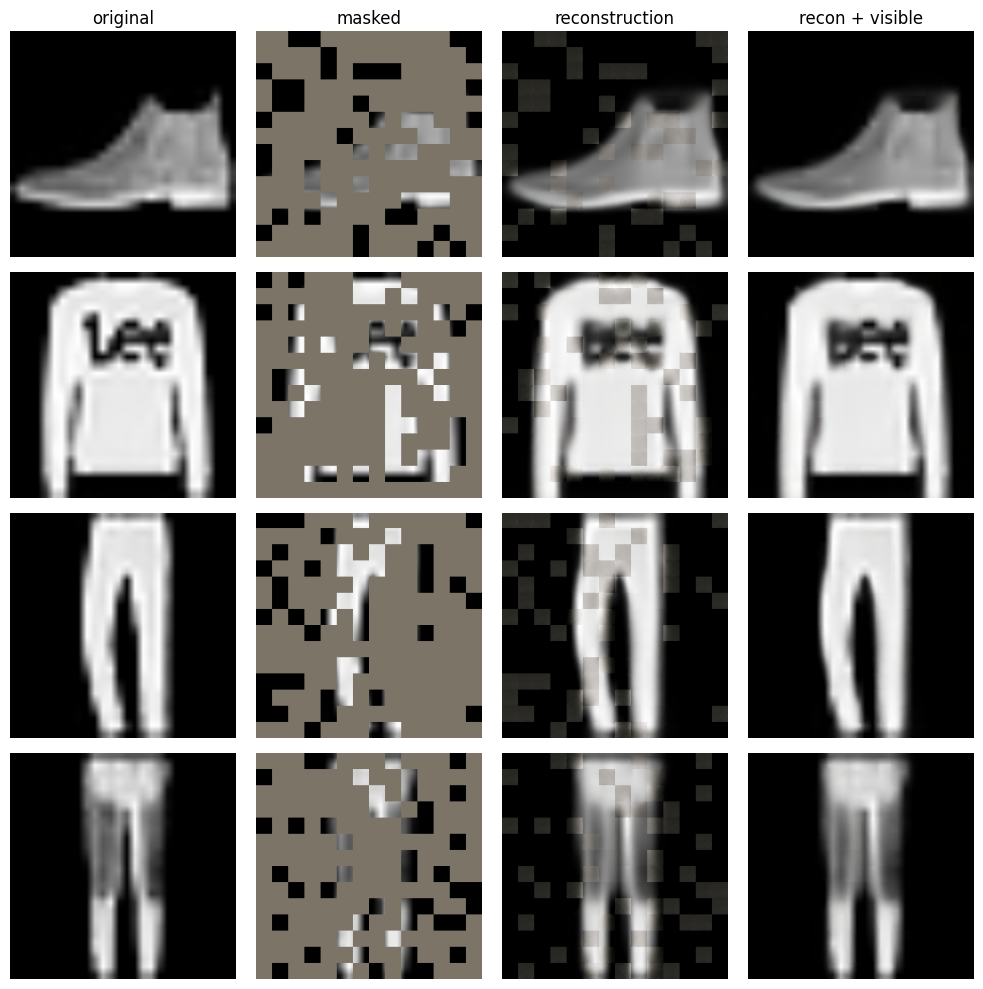

In [21]:
mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
std = torch.tensor(image_processor.image_std).view(3, 1, 1)

def to_img(t):
    # (3, H, W) 정규화 텐서 -> (H, W, 3) 이미지
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

@torch.no_grad()
def reconstruct(pixel_values, mask_ratio=0.75, seed=0):
    model.config.mask_ratio = mask_ratio
    torch.manual_seed(seed)
    out = model(pixel_values)
    pred = model.unpatchify(out.logits)                        # (N, 3, H, W)
    p = model.config.patch_size
    mask = out.mask.unsqueeze(-1).repeat(1, 1, p * p * 3)      # (N, L, p*p*3)
    mask = model.unpatchify(mask)                              # 1 = remove, 0 = keep
    masked = pixel_values * (1 - mask)
    paste = pixel_values * (1 - mask) + pred * mask          # visible patch는 원본으로 덮어쓰기
    return out.loss.item(), masked, pred, paste

loss, masked, pred, paste = reconstruct(pixel_values, mask_ratio=0.75)
print(f'loss (mask 75%) = {loss:.4f}')

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i in range(4):
    for j, (img, title) in enumerate([(pixel_values[i], 'original'), (masked[i], 'masked'),
                                      (pred[i], 'reconstruction'), (paste[i], 'recon + visible')]):
        axes[i, j].imshow(to_img(img)); axes[i, j].axis('off')
        if i == 0: axes[i, j].set_title(title)
plt.tight_layout(); plt.show()

### 3-2. masking ratio를 바꿔 보기
같은 이미지에 대해 masking ratio를 0.25 → 0.95로 바꿔 가며 loss와 재구성 결과를 비교합니다.

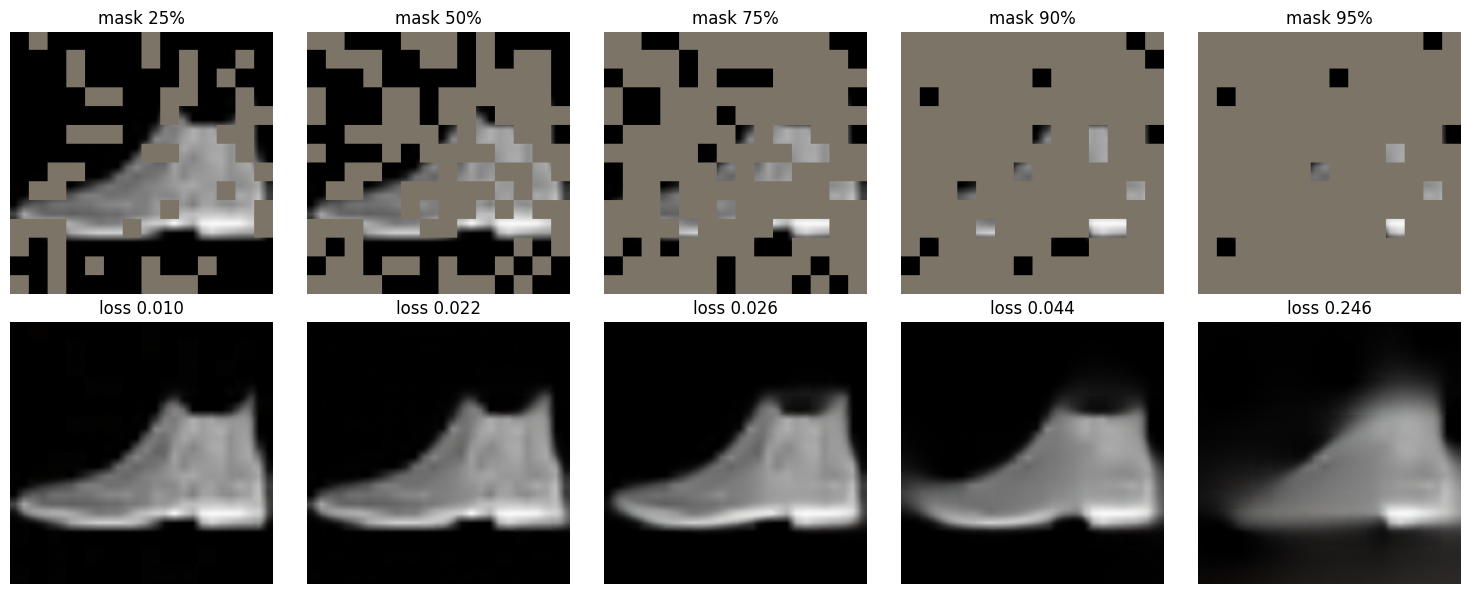

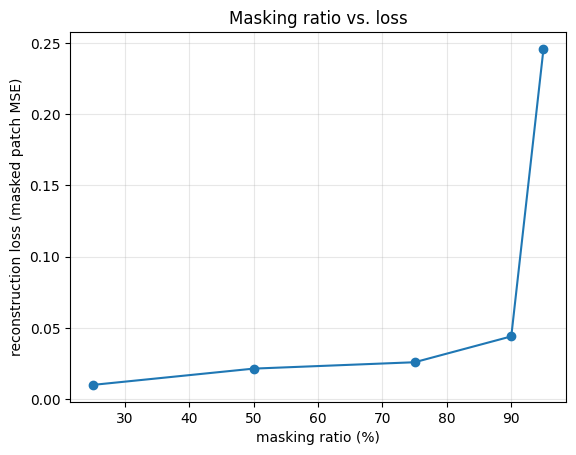

In [22]:
ratios = [0.25, 0.5, 0.75, 0.9, 0.95]
losses = []
fig, axes = plt.subplots(2, len(ratios), figsize=(3 * len(ratios), 6))
for k, r in enumerate(ratios):
    loss, masked, pred, paste = reconstruct(pixel_values[:1], mask_ratio=r)
    losses.append(loss)
    axes[0, k].imshow(to_img(masked[0])); axes[0, k].set_title(f'mask {int(r*100)}%'); axes[0, k].axis('off')
    axes[1, k].imshow(to_img(paste[0])); axes[1, k].set_title(f'loss {loss:.3f}'); axes[1, k].axis('off')
plt.tight_layout(); plt.show()

plt.plot([int(r * 100) for r in ratios], losses, marker='o')
plt.xlabel('masking ratio (%)'); plt.ylabel('reconstruction loss (masked patch MSE)')
plt.title('Masking ratio vs. loss'); plt.grid(alpha=.3); plt.show()
model.config.mask_ratio = 0.75   # 원래 값으로 복구

**Q8.** masking ratio가 커질수록 loss와 재구성 결과는 어떻게 변했나요? 이 결과와 논문 Fig. 5(75%가 최적)를 연결해, "복원이 잘 되는 것"과 "좋은 표현을 배우는 것"이 같은지 다른지 의견을 쓰세요.

> 답: masking ratio가 커질수록 보이는 패치가 줄어서 과제가 어려워지고 loss는 대체로 커지며 재구성 결과는 점점 흐릿해지고 원본과 달라짐. 논문 Fig 4를 보면 75%로 학습한 모델에 85%와 95%를 넣어도 결과가 그럴듯하긴 하지만 원본과 다른 모습으로 복원됨. 논문이 마스킹 비율별 loss 곡선을 직접 보여주진 않아서 이 부분은 노트북 출력으로 확인해야 하고 논문은 샘플링 방식 비교에서 같은 경향을 보여줌. block 마스킹은 더 어려운 과제라 training loss가 높고 복원도 흐렸고 grid 마스킹은 쉬운 과제라 loss가 낮고 복원이 선명했음.

**Q9.** `reconstruction` 열에서 visible patch 위치가 오히려 더 거칠게(블록처럼) 보였다면 그 이유는 무엇일까요? (Part 2의 Q6와 연결)

> 답: visible patch 위치가 더 거칠고 블록처럼 보인 이유는 그 위치에 학습 신호가 없기 때문임. Q6에서 본 대로 loss가 가려진 패치에서만 계산되므로 visible 위치의 출력은 정답에 맞추도록 학습된 적이 없음. 가려진 패치는 이웃 패치와 자연스럽게 이어지도록 학습되지만 visible 위치는 그런 제약이 없어서 패치마다 밝기와 색이 제각각인 결과가 나옴. 모델이 패치를 하나씩 독립적으로 출력하는 구조라 이 불일치가 패치 경계에서 블록 모양으로 드러남.

---
## (선택) Part 4. 토의 질문

1. 최적 masking ratio 75%는 데이터의 redundancy에 따라 달라질까요? 비디오·의료 영상·FashionMNIST처럼 배경이 단순한 이미지라면 어떨까요?
2. MAE의 "visible patch만 encoder에 넣기"는 ViT라서 가능한 설계입니다. CNN에 같은 아이디어를 적용하려면 무엇이 필요할까요?

> 답:

---
**참고 자료**
- He et al. (2022). *Masked Autoencoders Are Scalable Vision Learners*. CVPR. https://arxiv.org/abs/2111.06377
- 공식 코드: https://github.com/facebookresearch/mae (`models_mae.py`)
- Hugging Face ViTMAE 문서: https://huggingface.co/docs/transformers/model_doc/vit_mae
- 교재: 파이토치 트랜스포머를 활용한 자연어 처리와 컴퓨터비전 심층학습, 10장 ViT 실습 (p.609~624)